# 05 Projeto fatorial com dois fatores e replicações

O objetivo é avaliar como a quantidade de workers e o uso de cache alteram a latência média de uma API. A decisão é identificar quais mudanças reduzem a latência e verificar se o modelo descreve a variação entre sessões nas quatro configurações estudadas.

O experimento é um fatorial completo $2^2r$. Há dois fatores, dois níveis por fator e oito sessões independentes em cada configuração. Os dados são sintéticos e representam um protocolo de coleta definido antes da análise. A resposta é a latência média de uma sessão, em milissegundos.

O modelo, a tabela de sinais e a alocação da variação seguem Jain. A interpretação de efeitos, interações e diagnóstico é complementada por Montgomery.


In [1]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '05_projeto_22r'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)


## Objetivo, fatores e hipóteses operacionais

| Fator | Nível baixo | Nível alto | Hipótese operacional |
| --- | --- | --- | --- |
| A, workers | 2 workers | 6 workers | Mais workers podem reduzir a espera por atendimento |
| B, cache | Desativado | Ativado | O cache pode evitar acessos repetidos ao armazenamento |

O aumento de workers pode ter um efeito diferente quando o cache está ativado. Se o cache já remove parte do trabalho, a redução adicional de latência obtida com mais workers pode diminuir. Essa é a hipótese operacional de interação.

As hipóteses operacionais explicam a escolha dos fatores e dos níveis. Os testes estatísticos examinam coeficientes do modelo. Um mecanismo plausível não determina antecipadamente o resultado do teste.

## Protocolo e unidade experimental

Uma sessão completa é a unidade experimental. Cada sessão executa a mesma carga durante uma janela fixa, após um período de aquecimento definido no protocolo. A média das latências dessa janela fornece uma observação. As requisições internas da sessão não são replicações independentes do tratamento.

O hardware, a versão da API, o banco de dados, o conjunto de requisições e a concorrência permanecem fixos. O serviço é reiniciado entre sessões. O estado do cache é preparado novamente conforme o tratamento. A sequência das 32 sessões é aleatorizada antes da execução.

As oito colunas da matriz representam sessões independentes de cada configuração. Uma mesma coluna em linhas diferentes não define um par ou um bloco. O delineamento usado nas contas pressupõe aleatorização completa, replicação balanceada e ausência de observações faltantes.


In [2]:
nomes = ["Workers", "Cache"]
niveis_reais = [["2 workers", "6 workers"], ["Desativado", "Ativado"]]

# A ordem das linhas é a ordem padrão da tabela de sinais.
# A alterna a cada linha e B alterna a cada duas linhas.
niveis = np.array([[-1, -1], [1, -1], [-1, 1], [1, 1]])
r = 8
rng_dados = np.random.default_rng(20261019)
medias_geradoras = np.array([102.0, 77.0, 72.0, 61.0])
response = medias_geradoras[:, None] + rng_dados.normal(0.0, 3.5, (4, r))

# A permutação descreve a sequência temporal real deste exemplo sintético.
rng_ordem = np.random.default_rng(40817)
ordem_execucao = rng_ordem.permutation(response.size)

res = ajustar(response)
res["unidade"] = "ms"
display(pd.DataFrame(response, index=["A− B−", "A+ B−", "A− B+", "A+ B+"],
                     columns=[f"Sessão {j + 1}" for j in range(r)]))
print(f"Configurações {res['g']}")
print(f"Sessões por configuração {res['r']}")
print(f"Total de unidades experimentais {res['N']}")


Configurações 4
Sessões por configuração 8
Total de unidades experimentais 32


,Sessão 1,Sessão 2,Sessão 3,Sessão 4,Sessão 5,Sessão 6,Sessão 7,Sessão 8
A− B−,102.22,98.221,103.46,104.29,100.38,98.973,100.08,104.25
A+ B−,77.811,78.173,83.194,76.103,76.973,80.654,75.724,80.744
A− B+,76.033,69.701,73.293,69.112,81.75,77.919,69.69,70.777
A+ B+,58.896,51.041,63.739,59.746,61.079,66.842,61.785,58.257


## Dados e médias por configuração

A matriz preserva as respostas de cada sessão. As médias resumem as configurações, enquanto a dispersão dentro de cada linha fornece informação sobre o erro experimental. Substituir as oito sessões por uma única média eliminaria essa informação da análise.

A identificação de cada sessão acompanha seus níveis e sua posição temporal. Reorganizar os dados na ordem padrão facilita as contas, mas não altera a ordem em que o experimento foi executado.


In [3]:
tabela_dados = pd.DataFrame({
    "identificacao": [f"S{i + 1:02d}" for i in range(res['N'])],
    "A": np.repeat(niveis[:, 0], r),
    "B": np.repeat(niveis[:, 1], r),
    "latencia_ms": response.ravel(),
})
tabela_dados["ordem_execucao"] = np.argsort(ordem_execucao) + 1
display(tabela_dados.sort_values("ordem_execucao").reset_index(drop=True))
display(pd.DataFrame({
    "A": niveis[:, 0], "B": niveis[:, 1],
    "media_ms": response.mean(axis=1),
    "desvio_padrao_ms": response.std(axis=1, ddof=1),
}))


,identificacao,A,B,latencia_ms,ordem_execucao
0,S01,-1,-1,102.22,1
1,S25,1,1,58.896,2
2,S13,1,-1,76.973,3
3,S02,-1,-1,98.221,4
4,S28,1,1,59.746,5
5,S26,1,1,51.041,6
6,S12,1,-1,76.103,7
7,S15,1,-1,75.724,8
8,S32,1,1,58.257,9
9,S10,1,-1,78.173,10


,A,B,media_ms,desvio_padrao_ms
0,-1,-1,101.48,2.3922
1,1,-1,78.672,2.6144
2,-1,1,73.535,4.6238
3,1,1,60.173,4.6214


### Observações e médias por combinação

Cada ponto representa uma sessão. O pequeno deslocamento horizontal permite enxergar valores próximos e não modifica a resposta. O traço preto indica a média do tratamento. A combinação no eixo horizontal não representa a ordem de execução.

As barras mostram as médias e as hastes mostram ICs individuais de 90%. O erro padrão da média de uma combinação é $\sqrt{MSE/r}$, com $MSE=SSE/[g(r-1)]$ e $g=2^k$. Assim,

$$IC_{90}(\mu_i)=\bar y_i\pm t_{0{,}95,\,g(r-1)}\sqrt{\frac{MSE}{r}}.$$

Usamos t porque a variância dos erros é estimada pelas replicações. Com desvio padrão populacional conhecido, usaríamos z e esse desvio no lugar de $\sqrt{MSE}$. Os ICs pressupõem erros normais independentes com variância comum. Eles expressam a incerteza da média e não a dispersão de uma sessão individual. A sobreposição das hastes não substitui o teste de uma diferença entre médias.


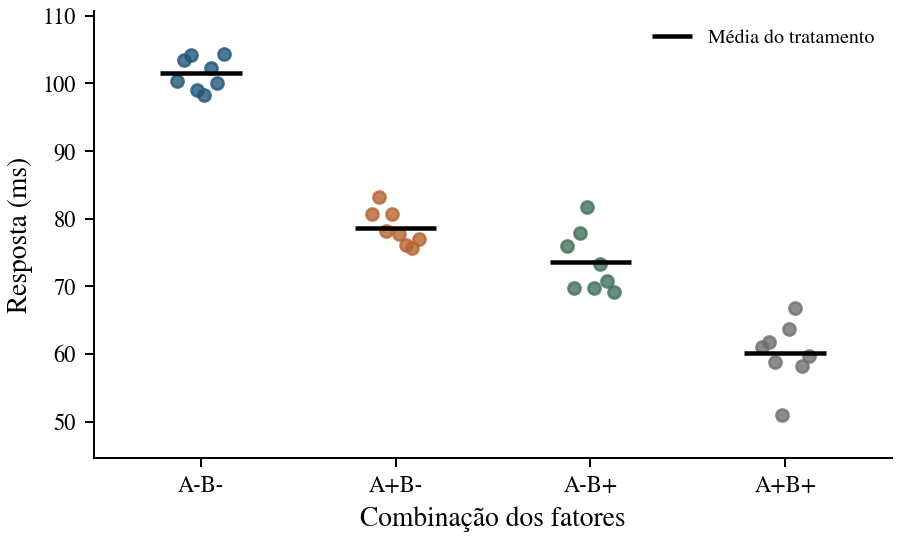

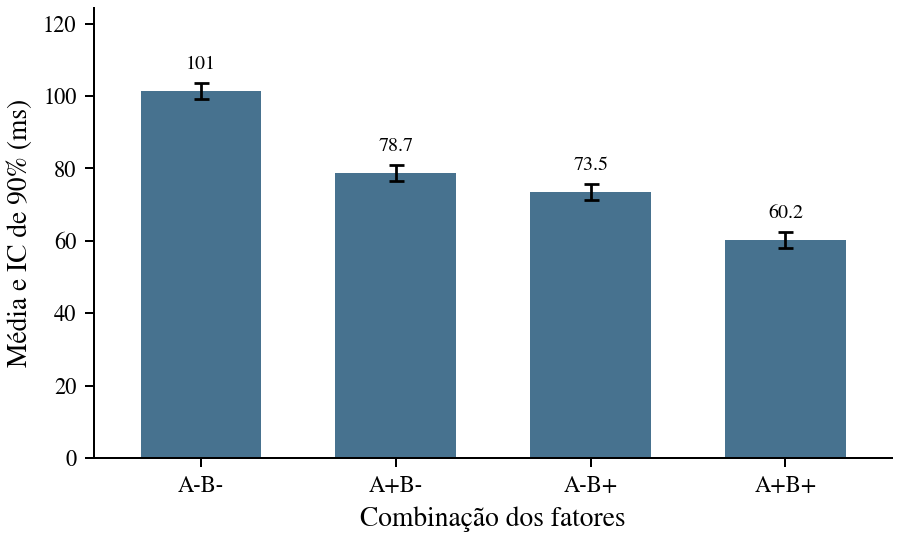

In [4]:
tabela_combinacoes = graficos_combinacoes(res, nomes, niveis_reais, "combinacoes")


## Modelo e tabela de sinais

Os fatores são codificados por $x_A,x_B\in\{-1,+1\}$. O modelo completo é

$$y_{ij}=q_0+q_Ax_{Ai}+q_Bx_{Bi}+q_{AB}x_{Ai}x_{Bi}+\varepsilon_{ij}.$$

O índice $i$ identifica a configuração e $j$ identifica a sessão. O termo $q_0$ é a média geral. Os termos $q_A$ e $q_B$ descrevem mudanças médias por unidade codificada. O termo $q_{AB}$ representa a interação.

Na nomenclatura de Jain, os termos $q$ são chamados efeitos. Na convenção de diferença entre alto e baixo, usada na interpretação fatorial de Montgomery, o efeito correspondente é $E_j=2q_j$. O intercepto não é multiplicado por dois.

Se $X_c$ reúne as quatro linhas da tabela de sinais e $\bar{\mathbf y}$ reúne as médias das configurações, a ortogonalidade fornece

$$X_c^{\mathsf T}X_c=4I,\qquad \widehat{\mathbf q}=\frac{1}{4}X_c^{\mathsf T}\bar{\mathbf y}.$$


In [5]:
display(pd.DataFrame(res["Xc"], columns=["I", "A", "B", "AB"]))
modelo_escrito(res, nomes=nomes, resposta="y")


,I,A,B,AB
0,1,-1,-1,1
1,1,1,-1,-1
2,1,-1,1,-1
3,1,1,1,1


$$\widehat{y}=78.47 - 9.043x_{A} - 11.61x_{B} + 2.362x_{A}x_{B}.$$

## Erro experimental e alocação da variação

O ajuste completo reproduz a média de cada configuração. O resíduo de uma sessão é sua diferença em relação a essa média, $\widehat\varepsilon_{ij}=y_{ij}-\bar y_i$.

O total corrigido pela média geral se decompõe em parcelas dos termos e do erro

$$SST=SS_A+SS_B+SS_{AB}+SSE.$$

Cada termo possui um grau de liberdade e $SS_j=4r\widehat q_j^2$. O erro possui $\nu=4(r-1)$ graus de liberdade. Assim,

$$MSE=\frac{SSE}{4(r-1)},\qquad s_e=\sqrt{MSE},\qquad s_q=\frac{s_e}{\sqrt{4r}}.$$

A participação de cada parcela é calculada em relação a $SST$. As participações dos termos e do erro somam 100%. Uma soma de quadrados mede magnitude e não informa a direção da mudança. A direção será lida nas estimativas e nos gráficos dos níveis.


,Fonte,SS,Variação alocada (%)
0,A,2617,34.905
1,B,4314.8,57.551
2,AB,178.6,2.3821
3,Erro,387.06,5.1625


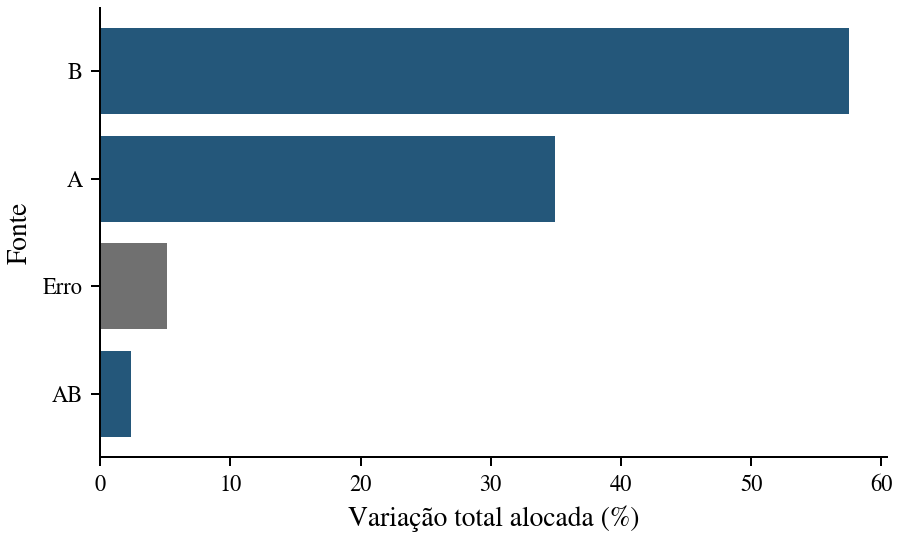

In [6]:
grafico_variacao(res, "05_variacao")


### Distribuições t e z nos intervalos

As convenções da aula usam $z_{1-\alpha/2}$ para um quantil da normal padrão e $t_{1-\alpha/2,\nu}$ para um quantil de Student. Para uma média de observações normais independentes, usamos z quando o desvio-padrão populacional $\sigma$ é conhecido. Quando $\sigma$ é estimado pela própria amostra, usamos t com os graus de liberdade da estimativa da variância.

No fatorial completo balanceado, $N=2^kr$ e $\nu=2^k(r-1)$. Como $\sigma$ é desconhecido, estimamos $s_e^2=SSE/\nu$ e construímos o IC individual de um coeficiente por

$$\widehat q_S\pm t_{1-\alpha/2,\nu}\frac{s_e}{\sqrt N}.$$

Se $\sigma$ fosse conhecido, substituiríamos $s_e$ por $\sigma$ e o quantil t por z. Para muitos graus de liberdade, t se aproxima de z. Ter mais de 30 observações não torna $\sigma$ conhecido nem exige abandonar t. A interpretação exata dos ICs clássicos pressupõe erros normais independentes com variância comum. Jain fornece a notação q e Montgomery apresenta essa relação com o modelo de regressão.

Os exemplos usam confiança de 90% e $\alpha=0{,}10$. O efeito alto menos baixo do contraste é $2q_S$. Seus dois limites também são multiplicados por dois. Os intervalos apresentados são individuais.


## Intervalos e testes dos coeficientes

Adotamos confiança de 90% e significância de 10%, definidas antes da inspeção dos resultados. Para cada termo explicativo, o teste bilateral examina

$$H_0\quad q_j=0,\qquad H_1\quad q_j\ne0.$$

Sob as premissas do modelo e $H_0$, a estatística $t_j=\widehat q_j/s_q$ segue a distribuição t com $\nu=4(r-1)$ graus de liberdade. O intervalo individual é

$$\widehat q_j\pm t_{0{,}95,\nu}s_q.$$

O valor p é a probabilidade, sob $H_0$ e as premissas do teste, de uma estatística pelo menos tão extrema quanto a observada. Um valor p menor que 0,10 leva à rejeição de $H_0$. Um valor maior não demonstra que o coeficiente seja nulo. O valor p não mede a probabilidade de $H_0$ ser verdadeira nem a importância prática da mudança.

Os intervalos apresentados são individuais. Sua leitura conjunta não fornece cobertura simultânea de 90% para todos os termos. Os limites e os erros padrão devem ser multiplicados por dois quando a estimativa é apresentada na escala de $E_j=2q_j$.


,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,-9.0433,0.65726,-10.161,-7.9252,-18.087,-13.759,5.538e-14,Sim
1,B,-11.612,0.65726,-12.73,-10.494,-23.224,-17.667,1.021e-16,Sim
2,AB,2.3625,0.65726,1.2444,3.4806,4.7249,3.5944,0.001232,Sim


**Efeito qA**

É significativo porque o valor-p 5.538e-14 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 1.021e-16 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 0.001232 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

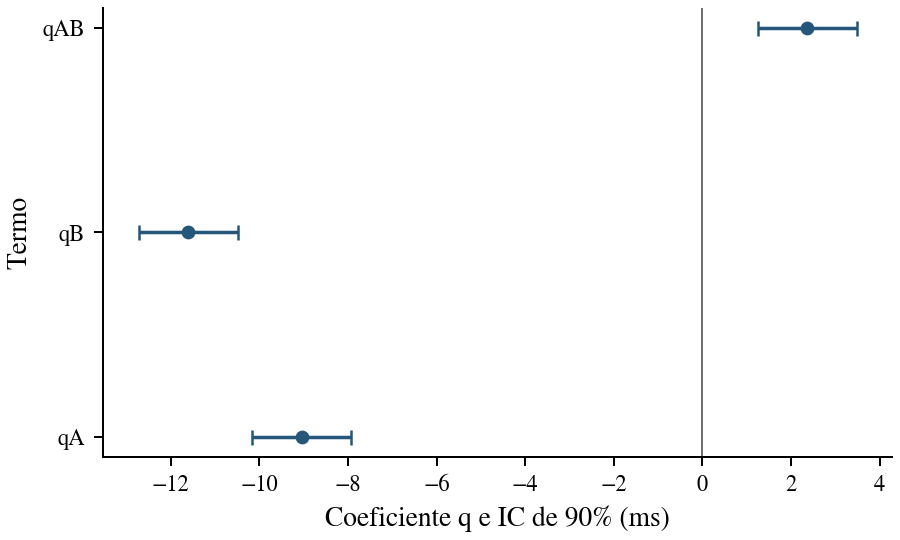

In [7]:
mostrar_resultados(res)
graficos_efeitos(res, "05_efeitos")


## ANOVA e significância global

O teste global compara o modelo completo com uma média constante. Suas hipóteses são

$$H_0\quad q_A=q_B=q_{AB}=0,$$
$$H_1\quad \text{pelo menos um desses coeficientes difere de zero}.$$

A estatística é

$$F=\frac{(SS_A+SS_B+SS_{AB})/3}{MSE}.$$

Sob $H_0$ e as premissas do modelo, usamos a distribuição F com 3 e $\nu$ graus de liberdade. A ANOVA também apresenta testes por termo. Para um termo com um grau de liberdade, $F_j=t_j^2$.

Um resultado global significativo evidencia alguma diferença entre as configurações. Ele não demonstra que todos os termos sejam relevantes e não valida as premissas. A significância precisa ser acompanhada pela magnitude dos efeitos e pela interpretação da interação.


### Como ler a ANOVA

A ANOVA organiza a mesma decomposição usada na alocação da variação.

| Coluna | Leitura |
| --- | --- |
| SS ou SQ | Soma de quadrados atribuída ao termo ou ao erro, na unidade da resposta ao quadrado |
| gl | Graus de liberdade usados naquela parcela |
| MS ou QM | Quadrado médio, calculado por SQ dividida por gl |
| F | Razão entre o quadrado médio do termo e o quadrado médio do erro |
| Valor-p | Probabilidade de um F pelo menos tão grande sob a hipótese nula e as condições do modelo |

No fatorial completo balanceado, cada termo possui um grau de liberdade. O erro possui $\nu=2^k(r-1)$ e seu quadrado médio é $MSE=SSE/\nu$. O total possui $N-1$ graus de liberdade. Assim,

$$F_S=\frac{QM_S}{MSE}=\frac{SS_S/1}{SSE/\nu}.$$

As referências são $F_{1,\nu}$ por termo e $F_{2^k-1,\nu}$ para o modelo. A decisão usa as hipóteses já apresentadas. Um valor-p menor ou igual a $\alpha$ leva à rejeição da hipótese correspondente. Um valor maior indica evidência insuficiente para rejeitá-la.

A alocação mostra $100SS_S/SST$. A ANOVA compara cada parcela com a variação entre réplicas por meio do MSE. Por isso, uma parcela pequena de SST ainda pode ser significativa quando o erro é pequeno. O teste não informa sozinho a direção ou a importância prática do efeito. As linhas de erro e total não recebem testes F próprios.


In [8]:
mostrar_anova(res)


,Fonte,SS,gl,MS,F,Valor-p
0,A,2617,1,2617,189.31,5.538e-14
1,B,4314.8,1,4314.8,312.14,1.021e-16
2,AB,178.6,1,178.6,12.92,0.001232
3,Erro,387.06,28,13.824,NaN,
4,Total,7497.5,31,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,171.46,3,28,4.039e-18


**Teste F global**

É significativo porque o valor-p 4.039e-18 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

## Fatores, níveis e interação

O gráfico de níveis resume as médias marginais. Cada média marginal de A combina os dois níveis de B. Por isso, ela pode esconder diferenças entre as condições de cache.

O gráfico de interação mantém o outro fator fixo. Linhas com inclinações diferentes indicam que a mudança entre os níveis de um fator depende do nível do outro. A interação é quantificada e testada pelo contraste correspondente, sem usar sobreposição de barras como regra de decisão.

Para A em um nível fixo de B, a diferença entre alto e baixo é

$$E_{A\mid x_B}=2(q_A+q_{AB}x_B).$$

A interpretação operacional deve preservar essa condição. Uma redução média na latência não determina que a mesma redução ocorra em todas as configurações.


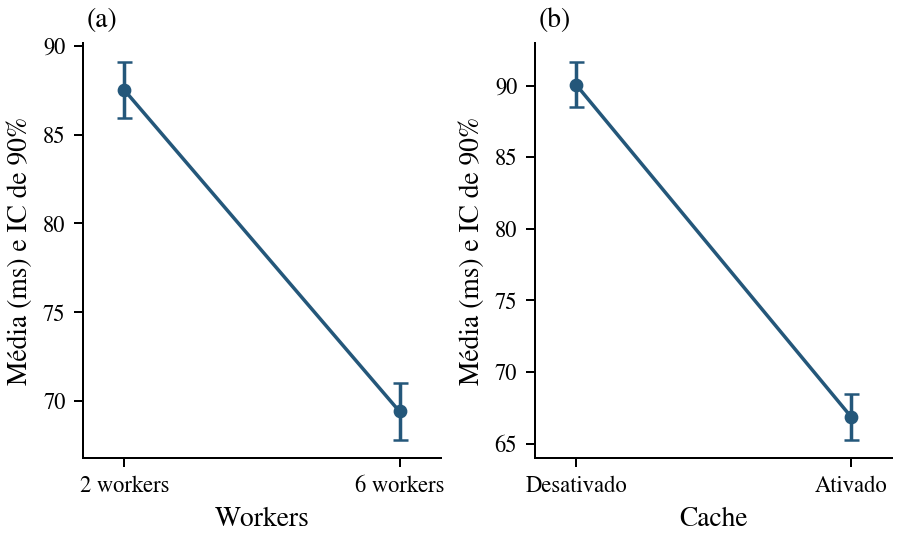

Painéis do gráfico. (a) Workers e Cache. (b) Cache e Workers.

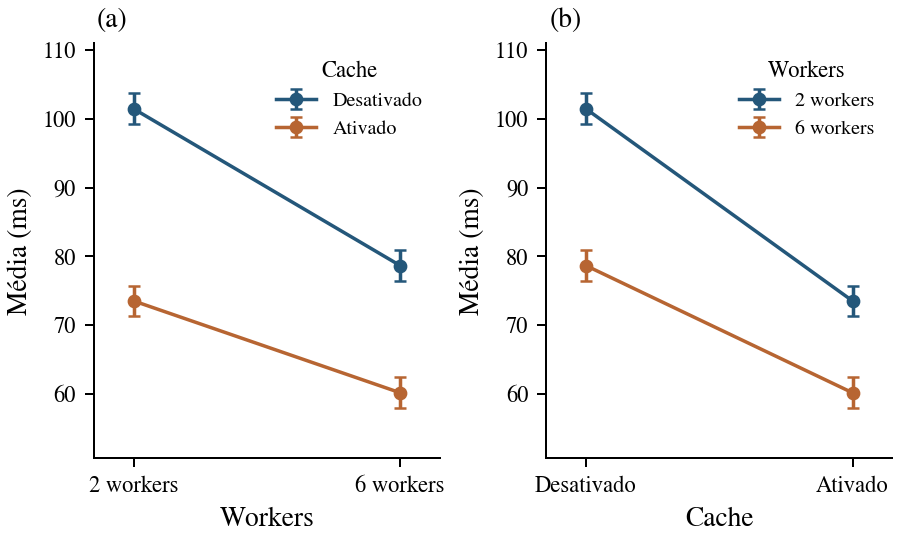

,condicao_cache,mudanca_6_menos_2_workers_ms
0,Desativado,-22.811
1,Ativado,-13.362


In [9]:
graficos_niveis(res, nomes, niveis_reais, "05_niveis", com_ic=True)
graficos_interacoes(res, nomes, niveis_reais, "05_interacoes", com_ic=True)
q = np.asarray(res["q"])
display(pd.DataFrame({
    "condicao_cache": niveis_reais[1],
    "mudanca_6_menos_2_workers_ms": [2 * (q[1] - q[3]), 2 * (q[1] + q[3])],
}))


### Condições do modelo

**Forma da resposta média**

O modelo precisa representar as médias nas condições estudadas. O completo reproduz as médias das combinações fatoriais. Isso deixa zero grau de liberdade para testar falta de ajuste entre esses pontos e não demonstra ausência de curvatura entre os níveis. O gráfico de resíduos contra os valores ajustados ajuda a investigar padrões, mas não certifica a forma do modelo.

**Homocedasticidade dos erros**

A variância deve permanecer aproximadamente constante. O teste de Levene centrado na mediana, conhecido como Brown e Forsythe, usa $H_0$ de variâncias iguais entre as combinações. Em $H_A$, pelo menos uma difere. Sua referência F é aproximada. O gráfico por combinação complementa o teste.

**Independência dos erros**

Os erros de sessões distintas não devem apresentar dependência sistemática. A ordem realmente executada é preservada no gráfico temporal. Durbin e Watson compara diferenças entre resíduos sucessivos com sua soma de quadrados. Valores próximos de 2 sugerem pouca associação de primeira ordem, valores menores sugerem associação positiva e maiores sugerem associação negativa. A referência usada para o valor-p simula erros normais independentes com variância comum sob o mesmo desenho. A alternativa procura dependência serial. O protocolo e o gráfico continuam necessários.

**Normalidade dos erros**

O Q-Q compara os quantis dos resíduos com os da normal. Nos testes de Shapiro e Wilk e de Kolmogorov e Smirnov, $H_0$ afirma normalidade dos erros e $H_A$ afirma desvio dessa forma. O segundo usa média e variância estimadas, como na formulação de Lilliefors. Como os resíduos compartilham parâmetros ajustados, os valores-p dos dois testes são calibrados com erros normais e o mesmo ajuste fatorial. Essa referência depende das demais condições do modelo. Durbin e Watson avalia dependência temporal, não normalidade.

Um teste significativo apresenta evidência contra sua hipótese nula. Um resultado não significativo indica evidência insuficiente para rejeitá-la. Nenhum valor-p demonstra que uma condição é verdadeira. A decisão considera os gráficos, a unidade experimental e o protocolo.


## Diagnóstico dos resíduos

O grid relaciona os resíduos ao ajuste, às configurações e à ordem real de execução, além de apresentar sua comparação com uma distribuição normal. A sequência temporal usada no diagnóstico é a sequência aleatorizada das 32 sessões.

No modelo completo, as médias residuais de cada configuração são zero por construção. Esse resultado algébrico não constitui um teste de adequação. O modelo tem quatro parâmetros para quatro médias de configuração e não deixa graus de liberdade para um teste de falta de ajuste nos vértices. Sua adequação entre os níveis não pode ser demonstrada apenas por essas quatro configurações.

A igualdade de variâncias é examinada por Levene com centralização na mediana, também associado a Brown e Forsythe. A normalidade é examinada por Shapiro-Wilk e por uma estatística de Kolmogorov-Smirnov com parâmetros estimados. A referência dos dois diagnósticos de normalidade é calibrada preservando a matriz do desenho. O valor p usual de KS para uma distribuição inteiramente especificada não corresponde a esse ajuste de parâmetros.

Durbin-Watson descreve a relação entre resíduos sucessivos. Seu resultado depende da ordem temporal. O diagnóstico não transforma a ausência de um padrão evidente em prova de independência. A definição das unidades e o protocolo de execução continuam sendo parte da avaliação.


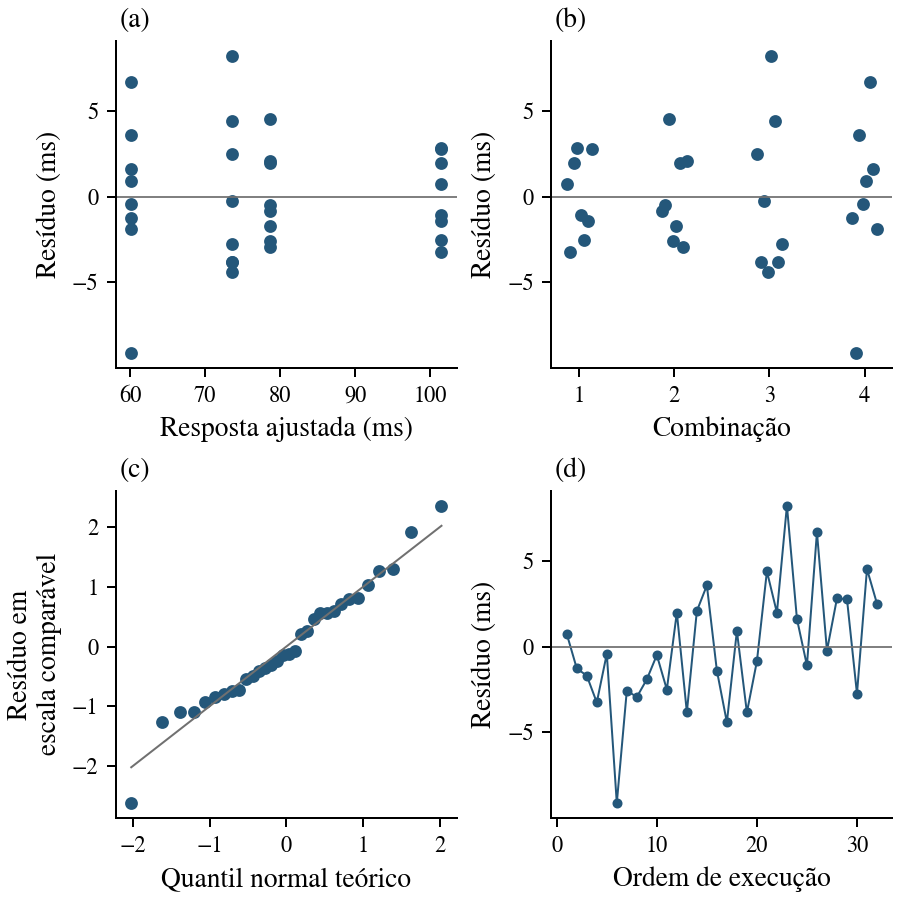

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,1.0488,0.3865,F aproximada
1,Shapiro e Wilk,0.97982,0.7764,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.089715,0.7202,Normal no mesmo desenho
3,Durbin e Watson,1.6894,0.4436,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.3865 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.7764 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.7202 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.4436 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

In [10]:
grid_residuos(res, ordem_execucao, "05_residuos")
resultado_diagnosticos = diagnosticos(res, ordem_execucao, "05_diagnosticos")


## Conclusão do experimento

As quatro configurações permitem separar as contribuições de workers, cache e interação para a variação observada. O gráfico da alocação inclui o erro experimental. Os gráficos dos efeitos e dos níveis acrescentam direção e unidade de medida, enquanto os intervalos expressam a precisão das estimativas.

Neste exemplo, o aumento de workers deve ser interpretado separadamente nos dois estados do cache. Essa comparação responde à hipótese operacional de que os mecanismos podem compartilhar parte do trabalho evitado. A combinação das médias marginais com o gráfico de interação impede atribuir ao fator uma mudança única em todas as condições.

A conclusão estatística depende da leitura conjunta das estimativas, dos valores p e dos diagnósticos. A normalidade aproximada dos resíduos não demonstra independência, assim como um teste de variâncias sem rejeição não prova variância constante. Um padrão temporal, uma dispersão incompatível com o erro comum ou uma observação sem explicação no protocolo exige investigar a causa antes de sustentar a inferência clássica.

As conclusões se restringem aos níveis, à carga, à unidade experimental e ao ambiente definidos no protocolo. O modelo completo descreve as médias das configurações estudadas. Essa propriedade não demonstra comportamento adequado fora delas.


## Referências

- Aula de Projeto e Análise de Experimentos. Material da disciplina.
- Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Material do autor](https://www.cse.wustl.edu/~jain/books/perf_sli.htm) e [errata](https://www.cse.wustl.edu/~jain/books/ftp/errors_all.pdf).
- Douglas C. Montgomery. *Design and Analysis of Experiments*. Planejamento fatorial, análise de variância e adequação de modelos. [Sumário da editora](https://bcs.wiley.com/he-bcs/Books?action=contents&bcsId=11447&itemId=1119492440).
- NIST/SEMATECH. [Delineamentos fatoriais de dois níveis](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3331.htm), [intervalos para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm) e [Levene](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35a.htm).
- SciPy. [Shapiro e Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html). Statsmodels. [Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) e [Durbin e Watson](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.durbin_watson.html). SciPy. [Calibração Monte Carlo com parâmetros estimados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Referências de implementação dos diagnósticos.
